In [1]:
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os
from sklearn.model_selection import train_test_split

In [2]:
labeled_data = pd.read_csv(r"D:\Project data\data\labeled_data.csv")
unlabeled_data = pd.read_csv(r"D:\Project data\data\unlabeled_data.csv")

labeled_data.columns

Index(['id', 'uuid', 'observed_on_string', 'observed_on', 'time_observed_at',
       'time_zone', 'user_id', 'user_login', 'user_name', 'created_at',
       'updated_at', 'quality_grade', 'license', 'url', 'sound_url',
       'tag_list', 'description', 'num_identification_agreements',
       'num_identification_disagreements', 'captive_cultivated',
       'oauth_application_id', 'place_guess', 'latitude', 'longitude',
       'positional_accuracy', 'private_place_guess', 'private_latitude',
       'private_longitude', 'public_positional_accuracy', 'geoprivacy',
       'taxon_geoprivacy', 'coordinates_obscured', 'positioning_method',
       'positioning_device', 'species_guess', 'scientific_name', 'common_name',
       'iconic_taxon_name', 'taxon_id', 'taxon_kingdom_name',
       'taxon_phylum_name', 'taxon_subphylum_name', 'taxon_superclass_name',
       'taxon_class_name', 'taxon_subclass_name', 'taxon_superorder_name',
       'taxon_order_name', 'taxon_suborder_name', 'taxon_superfami

['Cuculiformes', 'Piciformes', 'Coleoptera', 'Casuariiformes', 'Anura', 'Strigiformes', 'Dasyuromorphia', 'Eulipotyphla', 'Accipitriformes', 'Primates', 'Charadriiformes', 'Stylommatophora', 'Chiroptera', 'Cathartiformes', 'Hymenoptera', 'Didelphimorphia', 'Myida', 'Hemiptera', 'Decapoda', 'Suliformes', 'Orthoptera', 'Spirobolida', 'Hyracoidea', 'Sirenia', 'Diptera', 'Psittaciformes', 'Gruiformes', 'Falconiformes', 'Araneae', 'Chitonida', 'Coraciiformes', 'Rosales', 'Pilosa', 'Ericales', 'Pinales', 'Sphenisciformes', 'Tubulidentata', 'Ciconiiformes', 'Venerida', 'Isopoda', 'Rhynchocephalia', 'Gentianales', 'Opiliones', 'Monotremata', 'Adapedonta', 'Apodiformes', 'Procellariiformes', 'Neuroptera', 'Hypocreales', 'Caudata', 'Dermaptera', 'Crassiclitellata', 'Cingulata', 'Camarodonta', 'Podargiformes']
Number of Orders with 30 or fewer samples: 55


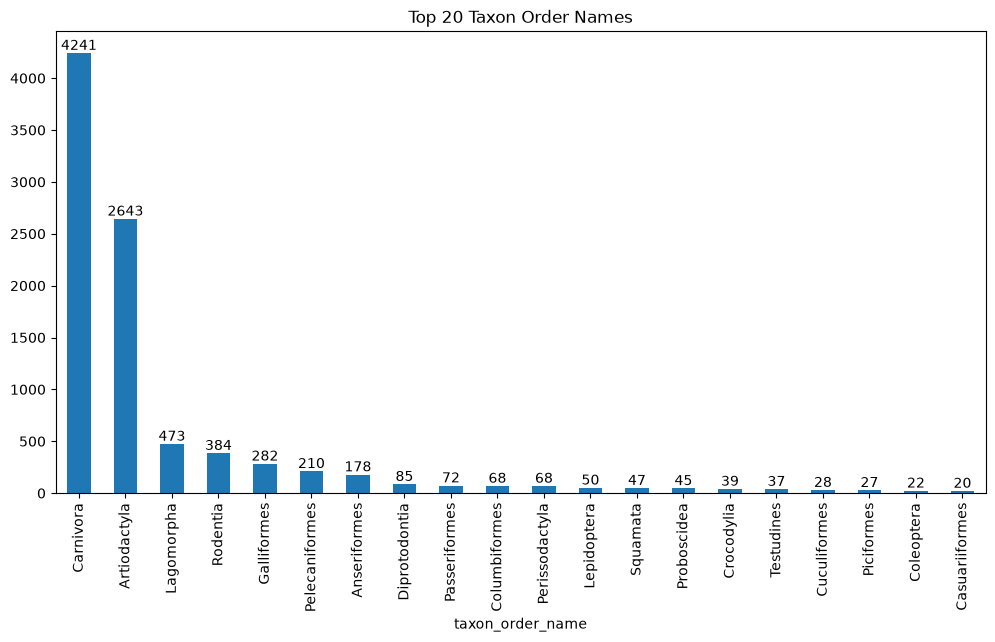

In [3]:
# plot the distribution of the labels in the labeled data
counts = labeled_data["taxon_order_name"].value_counts().head(20)
ax = counts.plot(kind="bar", figsize=(12, 6), title="Top 20 Taxon Order Names")
ax.bar_label(ax.containers[0])

# identify rare classes (those with 30 or fewer samples) in the labeled data
rare_classes = labeled_data["taxon_order_name"].value_counts()
rare_classes = rare_classes[rare_classes <= 30].index.tolist()

print(rare_classes)

# return the number of orders with 30 or fewer samples
print(f"Number of Orders with 30 or fewer samples: {len(rare_classes)}")

# there are many classes with very few samples, so we will filter out classes with less than 30 samples before training the model. This will help the model learn better and avoid overfitting to rare classes.


In [4]:
# predictions are made on the taxon_order_name column, so we need to ensure that this column is present and clean in the labeled data
LABEL_COLUMN = 'taxon_order_name' 

# remove rows where the image failed to download
df_labeled = labeled_data[~labeled_data['local_image_path'].isin(['Download Error', 'No URL Provided'])]
# drop rows where the label is missing
df_labeled_clean = df_labeled.dropna(subset=[LABEL_COLUMN]) 

# ensure labels are strings
df_labeled_clean[LABEL_COLUMN] = df_labeled_clean[LABEL_COLUMN].astype(str)

# count the number of samples per class and filter out classes 
class_counts = df_labeled[LABEL_COLUMN].value_counts()

# add a minimum sample threshold to filter out classes with too few samples
MIN_SAMPLES = 30
valid_classes = class_counts[class_counts >= MIN_SAMPLES].index

# filter the dataset to only include valid classes
df_filtered = df_labeled[df_labeled[LABEL_COLUMN].isin(valid_classes)].copy()

print(f"Original dataset size: {len(df_labeled)}")
print(f"Filtered dataset size: {len(df_filtered)}")
print(f"Dropped {len(class_counts) - len(valid_classes)} classes with too few images.")

Original dataset size: 9274
Filtered dataset size: 8919
Dropped 55 classes with too few images.


In [5]:
# split the labeled data into training and testing sets
df_temp, df_test = train_test_split(df_filtered, test_size=0.15, random_state=42, stratify=df_filtered[LABEL_COLUMN])

# split the remaining data into training and validation sets
df_train, df_val = train_test_split(df_temp, test_size=0.20, random_state=42, stratify=df_temp[LABEL_COLUMN])

# force a copy to avoid "SettingWithCopy" issue
df_train = df_train.copy()
df_val = df_val.copy()
df_test = df_test.copy()

# convert the label column to string and strip whitespace for all datasets
df_train[LABEL_COLUMN] = df_train[LABEL_COLUMN].astype(str).str.strip()
df_val[LABEL_COLUMN] = df_val[LABEL_COLUMN].astype(str).str.strip()
df_test[LABEL_COLUMN] = df_test[LABEL_COLUMN].astype(str).str.strip()

unlabeled_paths = unlabeled_data['local_image_path'].values

# helper function to process unlabeled images
def process_unlabeled(file_path):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [224, 224])
    return img / 255.0

unlabeled_dataset = tf.data.Dataset.from_tensor_slices(unlabeled_paths)
# Important: Do not shuffle here, so predictions map perfectly back to the DataFrame
unlabeled_dataset = unlabeled_dataset.map(process_unlabeled).batch(32)

# create the data generator
datagen = ImageDataGenerator(rescale=1./255)

print(f"Training rows: {len(df_train)}")
print(f"Validation rows: {len(df_val)}")

# create a sorted list of all valid classes for consistency across datasets
all_classes = sorted(list(valid_classes.astype(str)))

print(f"Master class list contains {len(all_classes)} classes.")

print(all_classes)

# create the labeled training dataset
train_dataset = datagen.flow_from_dataframe(
    dataframe=df_train,
    x_col='local_image_path',
    y_col=LABEL_COLUMN,
    classes=all_classes,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical', 
    subset='training'
)

print(f"Total rows in df_val: {len(df_val)}")

# create the labeled validation dataset
val_dataset = datagen.flow_from_dataframe(
    dataframe=df_val,
    x_col='local_image_path',
    y_col=LABEL_COLUMN, 
    classes=all_classes,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# create the labeled test dataset
test_dataset = datagen.flow_from_dataframe(
    dataframe=df_test,
    x_col='local_image_path',
    y_col=LABEL_COLUMN,
    classes=all_classes,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False # CRITICAL: Must be False so predictions align with the DataFrame rows
)

Training rows: 6064
Validation rows: 1517
Master class list contains 16 classes.
['Anseriformes', 'Artiodactyla', 'Carnivora', 'Columbiformes', 'Crocodylia', 'Diprotodontia', 'Galliformes', 'Lagomorpha', 'Lepidoptera', 'Passeriformes', 'Pelecaniformes', 'Perissodactyla', 'Proboscidea', 'Rodentia', 'Squamata', 'Testudines']
Found 6051 validated image filenames belonging to 16 classes.


c:\Users\bryso\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\legacy\preprocessing\image.py:919: UserWarning: Found 13 invalid image filename(s) in x_col="local_image_path". These filename(s) will be ignored.
  warnings.warn(


Total rows in df_val: 1517
Found 1513 validated image filenames belonging to 16 classes.


c:\Users\bryso\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\legacy\preprocessing\image.py:919: UserWarning: Found 4 invalid image filename(s) in x_col="local_image_path". These filename(s) will be ignored.
  warnings.warn(


Found 1333 validated image filenames belonging to 16 classes.


c:\Users\bryso\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\legacy\preprocessing\image.py:919: UserWarning: Found 5 invalid image filename(s) in x_col="local_image_path". These filename(s) will be ignored.
  warnings.warn(


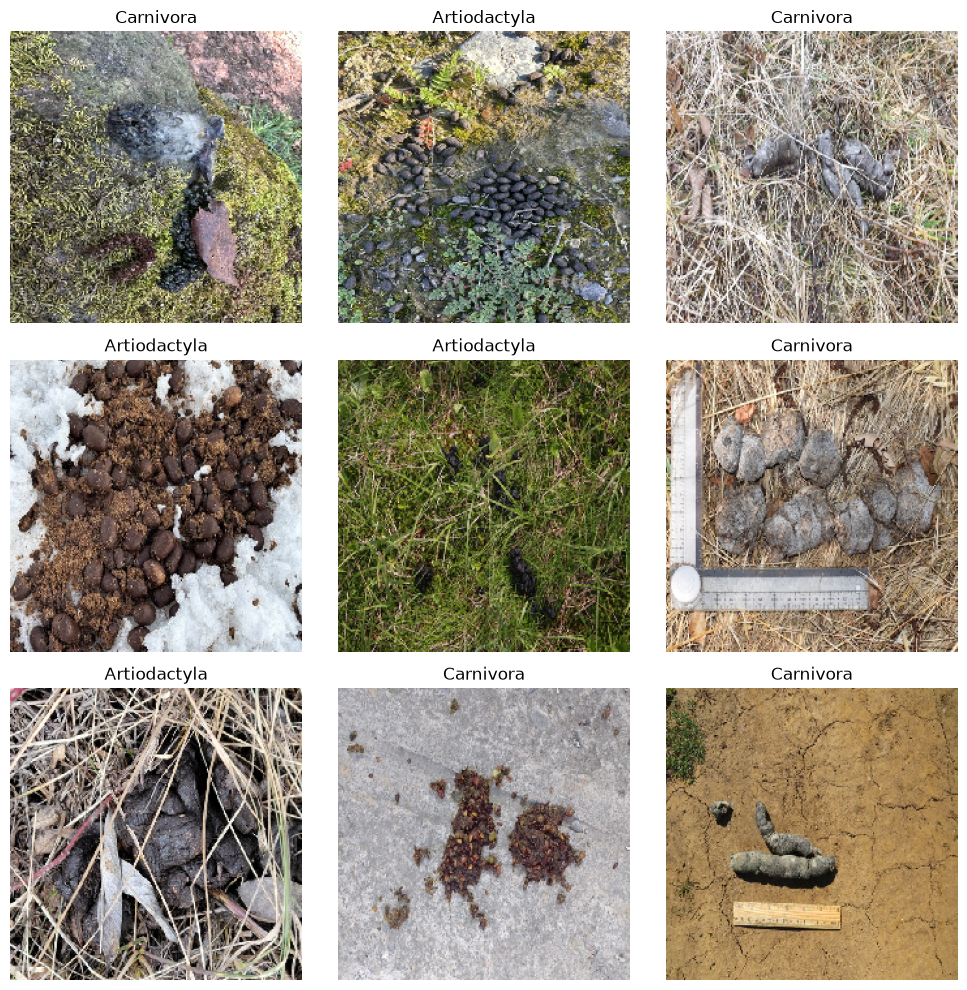

In [6]:
# sample a batch from the training dataset to verify everything is working
images, one_hot_labels = next(train_dataset)

# get the dictionary that maps class names to numbers from the generator
class_indices = train_dataset.class_indices

# reverse it so we can look up names by their number: {0: 'Cat', 1: 'Dog', ...}
index_to_class = {v: k for k, v in class_indices.items()}

# set up a matplotlib figure (e.g., a 3x3 grid)
plt.figure(figsize=(10, 10))

for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    
    img = images[i]
    
    # convert the one-hot array back to a single integer index
    label_index = np.argmax(one_hot_labels[i])
    
    # look up the actual string name
    class_name = index_to_class[label_index]
    
    # plot the image and label
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# base model architecture
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, MaxPooling2D, GlobalAveragePooling2D, Conv2D, BatchNormalization, Dropout


base_model = Sequential()

base_model.add(Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(224, 224, 3)))
base_model.add(BatchNormalization())
base_model.add(MaxPooling2D(pool_size=(2, 2)))

base_model.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
base_model.add(BatchNormalization())
base_model.add(MaxPooling2D(pool_size=(2, 2)))

base_model.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
base_model.add(BatchNormalization())
base_model.add(MaxPooling2D(pool_size=(2, 2)))

base_model.add(Conv2D(256, (3, 3), padding='same', activation='relu'))
base_model.add(BatchNormalization())
base_model.add(MaxPooling2D(pool_size=(2, 2)))

base_model.add(GlobalAveragePooling2D())

base_model.add(Dropout(0.3)) 

base_model.add(Dense(128, activation='relu'))
base_model.add(Dense(len(valid_classes), activation='softmax'))

base_model.compile(
    optimizer='adam', 
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.F1Score(average='macro', name='f1_score'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)
base_model.summary()

c:\Users\bryso\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         2,064 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 480,592 (1.83 MB)

 Trainable params: 479,632 (1.83 MB)

 Non-trainable params: 960 (3.75 KB)

In [8]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import datetime

early_stopping = EarlyStopping(
    monitor='val_loss',        # watch the validation loss
    patience=5,                # wait 5 epochs for improvement before stopping
    restore_best_weights=True, # automatically load the best weights when stopped
    verbose=1                  # print a message when it stops
)

model_checkpoint = ModelCheckpoint(
    filepath='D:/Project data/models/base_model_' + datetime.datetime.now().strftime("%Y%m%d-%H%M%S") + '.keras', # use .keras extension for modern Keras to load models with tf.keras.models.load_model()
    monitor='val_loss',                    
    save_best_only=True,                    # only save if the model improved
    verbose=1
)

In [9]:
# train the model
from tensorflow.keras.callbacks import TensorBoard


log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = TensorBoard(log_dir=log_dir, histogram_freq=1)

callbacks_list = [early_stopping, model_checkpoint, tensorboard_callback]

tensorboard_callback = TensorBoard(
    log_dir=log_dir, 
    histogram_freq=1,   
    write_graph=True    
)

history = base_model.fit(
    train_dataset,
    epochs=20,
    validation_data=val_dataset,
    callbacks=callbacks_list
)

Epoch 1/20
 19/190 ━━━━━━━━━━━━━━━━━━━━ 4:57 2s/step - accuracy: 0.4095 - auc: 0.8211 - f1_score: 0.0572 - loss: 2.0756 - precision: 0.4656 - recall: 0.2007

KeyboardInterrupt: 

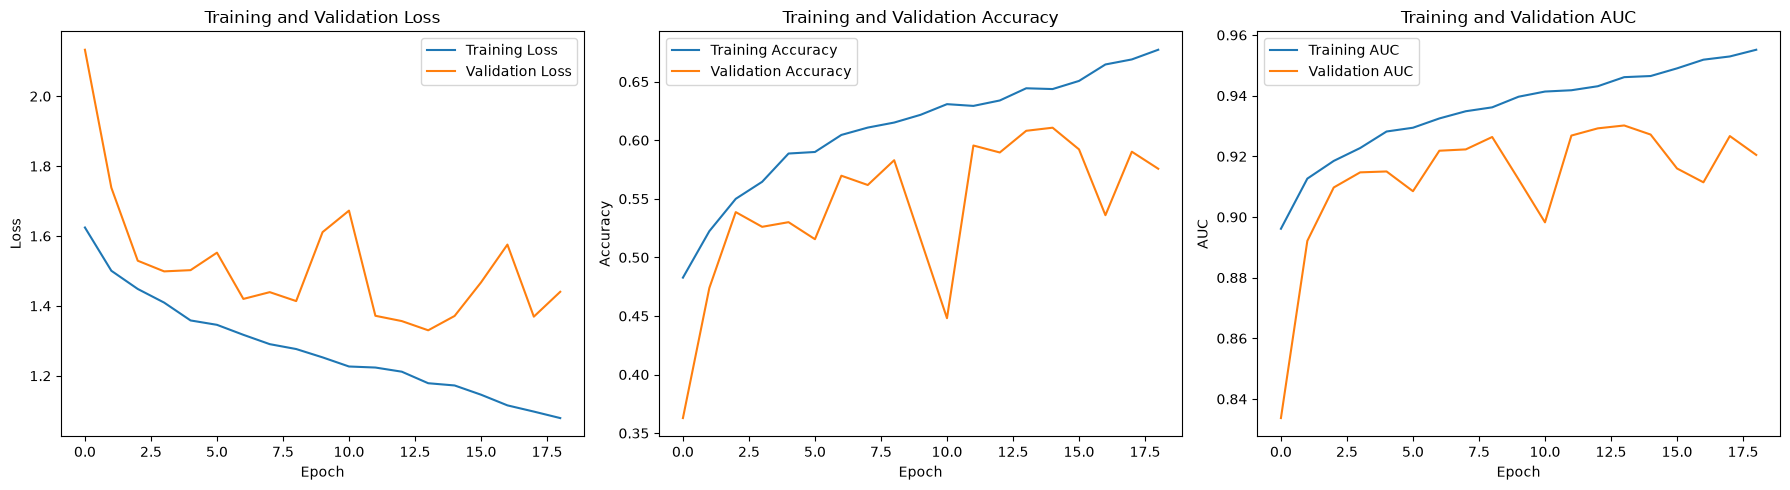

In [ ]:
# Create a single figure with 3 subplots side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Loss Subplot
axes[0].plot(history.history['loss'], label='Training Loss')
axes[0].plot(history.history['val_loss'], label='Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()

# 2. Accuracy Subplot
axes[1].plot(history.history['accuracy'], label='Training Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training and Validation Accuracy')
axes[1].legend()

# 3. AUC Subplot
axes[2].plot(history.history['auc'], label='Training AUC')
axes[2].plot(history.history['val_auc'], label='Validation AUC')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('AUC')
axes[2].set_title('Training and Validation AUC')
axes[2].legend()

# 4. F1 Score Subplot
axes[3].plot(history.history['f1_score'], label='Training F1 Score')
axes[3].plot(history.history['val_f1_score'], label='Validation F1 Score')
axes[3].set_xlabel('Epoch')
axes[3].set_ylabel('F1 Score')
axes[3].set_title('Training and Validation F1 Score')
axes[3].legend()

# 5. Precision Subplot
axes[4].plot(history.history['precision'], label='Training Precision')
axes[4].plot(history.history['val_precision'], label='Validation Precision')
axes[4].set_xlabel('Epoch')
axes[4].set_ylabel('Precision')
axes[4].set_title('Training and Validation Precision')
axes[4].legend()

# Automatically adjust spacing so titles and labels don't overlap
plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.models import load_model
import glob

model_dir = 'D:/Project data/models/'

list_of_files = glob.glob(model_dir + 'base_model_*.keras')

latest_model_path = max(list_of_files, key=os.path.getctime)

print(f"Loading the most recent model: {latest_model_path}")

final_model = load_model(latest_model_path)

test_results = final_model.evaluate(test_dataset, verbose=1)

for metric_name, metric_value in zip(final_model.metrics_names, test_results):
    print(f"{metric_name.capitalize()}: {metric_value:.4f}")
